### AI POWERED : ENERGY CONSUMPTION INTELLIGENCE SYSTEM

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("energy_consumption.csv")

### 1. Data Understanding

In [4]:
df.shape

(10000, 13)

In [5]:
df.head()

,Timestamp,Energy_Consumption_kWh,Temperature_C,Humidity_Percent,Occupancy,Electricity_Price_per_kWh,Day_Type,Season,Weather_Condition,House_Type,HVAC_Status,Water_Heater_Status,Anomaly
0,2024-01-01 00:00:00,2.32,26.89,78.37,1,3.82,Weekday,Winter,Sunny,Apartment,OFF,OFF,0
1,2024-01-01 01:00:00,1.50,24.40,87.74,1,3.83,Weekday,Winter,Rainy,Apartment,OFF,OFF,0
2,2024-01-01 02:00:00,5.60,24.60,71.46,2,3.77,Weekday,Winter,Cloudy,Apartment,ON,OFF,0
3,2024-01-01 03:00:00,1.50,24.03,80.42,1,3.89,Weekday,Winter,Sunny,Independent House,OFF,OFF,0
4,2024-01-01 04:00:00,1.63,23.82,77.08,2,3.66,Weekday,Winter,Sunny,Independent House,OFF,OFF,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Timestamp                  10000 non-null  object 
 1   Energy_Consumption_kWh     10000 non-null  float64
 2   Temperature_C              10000 non-null  float64
 3   Humidity_Percent           10000 non-null  float64
 4   Occupancy                  10000 non-null  int64  
 5   Electricity_Price_per_kWh  10000 non-null  float64
 6   Day_Type                   10000 non-null  object 
 7   Season                     10000 non-null  object 
 8   Weather_Condition          10000 non-null  object 
 9   House_Type                 10000 non-null  object 
 10  HVAC_Status                10000 non-null  object 
 11  Water_Heater_Status        10000 non-null  object 
 12  Anomaly                    10000 non-null  int64  
dtypes: float64(4), int64(2), object(7)
memory usage

In [7]:
df.columns

Index(['Timestamp', 'Energy_Consumption_kWh', 'Temperature_C',
       'Humidity_Percent', 'Occupancy', 'Electricity_Price_per_kWh',
       'Day_Type', 'Season', 'Weather_Condition', 'House_Type', 'HVAC_Status',
       'Water_Heater_Status', 'Anomaly'],
      dtype='object')

In [8]:
df.describe()

,Energy_Consumption_kWh,Temperature_C,Humidity_Percent,Occupancy,Electricity_Price_per_kWh,Anomaly
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,9.917056,26.427605,76.846589,1.663700,4.773437,0.012000
std,5.926119,3.576525,9.949923,1.217025,0.795498,0.108891
min,1.500000,18.000000,49.950000,0.000000,3.350000,0.000000
25%,5.180000,23.730000,69.060000,1.000000,3.930000,0.000000
50%,9.640000,26.110000,76.300000,2.000000,4.860000,0.000000
75%,14.130000,28.580000,83.322500,2.000000,5.140000,0.000000
max,69.420000,38.000000,98.000000,4.000000,6.490000,1.000000


In [9]:
df.isnull().sum()

Timestamp                    0
Energy_Consumption_kWh       0
Temperature_C                0
Humidity_Percent             0
Occupancy                    0
Electricity_Price_per_kWh    0
Day_Type                     0
Season                       0
Weather_Condition            0
House_Type                   0
HVAC_Status                  0
Water_Heater_Status          0
Anomaly                      0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
9995    False
9996    False
9997    False
9998    False
9999    False
Length: 10000, dtype: bool

In [12]:
df.nunique()

Timestamp                    10000
Energy_Consumption_kWh        2089
Temperature_C                 1634
Humidity_Percent              3465
Occupancy                        5
Electricity_Price_per_kWh      275
Day_Type                         2
Season                           3
Weather_Condition                3
House_Type                       3
HVAC_Status                      2
Water_Heater_Status              2
Anomaly                          2
dtype: int64

### 2.Timestamp Analysis

In [13]:
df["Timestamp"] = pd.to_datetime(df["Timestamp"])

In [14]:
df["Timestamp"].dtype

dtype('<M8[ns]')

In [15]:
print(df["Timestamp"].min())
print(df["Timestamp"].max())
print(df["Timestamp"].is_monotonic_increasing)

2024-01-01 00:00:00
2025-02-20 15:00:00
True


In [16]:
expected = pd.date_range(
    start=df["Timestamp"].min(),
    end=df["Timestamp"].max(),
    freq="h"
)

missing_timestamps = expected.difference(df["Timestamp"])

print("Missing timestamps:", len(missing_timestamps))

Missing timestamps: 0


In [17]:
df["Timestamp"].dt.hour
df["Timestamp"].dt.day
df["Timestamp"].dt.month
df["Timestamp"].dt.dayofweek

0       0
1       0
2       0
3       0
4       0
       ..
9995    3
9996    3
9997    3
9998    3
9999    3
Name: Timestamp, Length: 10000, dtype: int32

In [18]:
df["Hour"] = df["Timestamp"].dt.hour
df["Day"] = df["Timestamp"].dt.day
df["Month"] = df["Timestamp"].dt.month
df["DayOfWeek"] = df["Timestamp"].dt.dayofweek
df["DayName"] = df["Timestamp"].dt.day_name()
df["IsWeekend"] = df["Timestamp"].dt.dayofweek >= 5

In [19]:
df.head()

,Timestamp,Energy_Consumption_kWh,Temperature_C,Humidity_Percent,Occupancy,Electricity_Price_per_kWh,Day_Type,Season,Weather_Condition,House_Type,HVAC_Status,Water_Heater_Status,Anomaly,Hour,Day,Month,DayOfWeek,DayName,IsWeekend
0,2024-01-01 00:00:00,2.32,26.89,78.37,1,3.82,Weekday,Winter,Sunny,Apartment,OFF,OFF,0,0,1,1,0,Monday,False
1,2024-01-01 01:00:00,1.50,24.40,87.74,1,3.83,Weekday,Winter,Rainy,Apartment,OFF,OFF,0,1,1,1,0,Monday,False
2,2024-01-01 02:00:00,5.60,24.60,71.46,2,3.77,Weekday,Winter,Cloudy,Apartment,ON,OFF,0,2,1,1,0,Monday,False
3,2024-01-01 03:00:00,1.50,24.03,80.42,1,3.89,Weekday,Winter,Sunny,Independent House,OFF,OFF,0,3,1,1,0,Monday,False
4,2024-01-01 04:00:00,1.63,23.82,77.08,2,3.66,Weekday,Winter,Sunny,Independent House,OFF,OFF,0,4,1,1,0,Monday,False


In [20]:
df.tail()

,Timestamp,Energy_Consumption_kWh,Temperature_C,Humidity_Percent,Occupancy,Electricity_Price_per_kWh,Day_Type,Season,Weather_Condition,House_Type,HVAC_Status,Water_Heater_Status,Anomaly,Hour,Day,Month,DayOfWeek,DayName,IsWeekend
9995,2025-02-20 11:00:00,5.59,25.69,60.66,1,5.22,Weekday,Winter,Cloudy,Independent House,OFF,OFF,0,11,20,2,3,Thursday,False
9996,2025-02-20 12:00:00,6.17,22.71,64.43,0,5.14,Weekday,Winter,Cloudy,Apartment,OFF,OFF,0,12,20,2,3,Thursday,False
9997,2025-02-20 13:00:00,9.65,25.32,68.86,2,4.93,Weekday,Winter,Cloudy,Apartment,OFF,OFF,0,13,20,2,3,Thursday,False
9998,2025-02-20 14:00:00,10.14,25.37,63.75,2,5.06,Weekday,Winter,Sunny,Apartment,ON,OFF,0,14,20,2,3,Thursday,False
9999,2025-02-20 15:00:00,13.10,26.36,68.33,2,5.05,Weekday,Winter,Sunny,Apartment,ON,ON,0,15,20,2,3,Thursday,False


In [21]:
print("Start:", df["Timestamp"].min())
print("End:", df["Timestamp"].max())

print("\nTimestamp frequency:")
print(df["Timestamp"].diff().value_counts().head())

print("\nDuplicate timestamps:")
print(df["Timestamp"].duplicated().sum())

Start: 2024-01-01 00:00:00
End: 2025-02-20 15:00:00

Timestamp frequency:
Timestamp
0 days 01:00:00    9999
Name: count, dtype: int64

Duplicate timestamps:
0


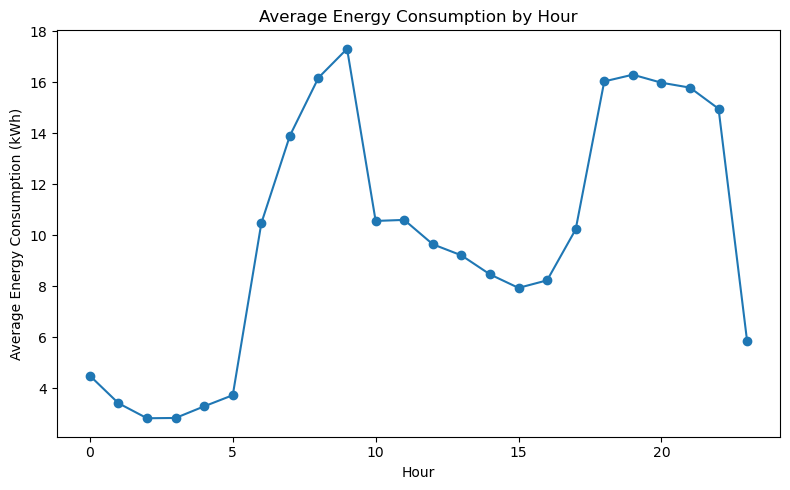

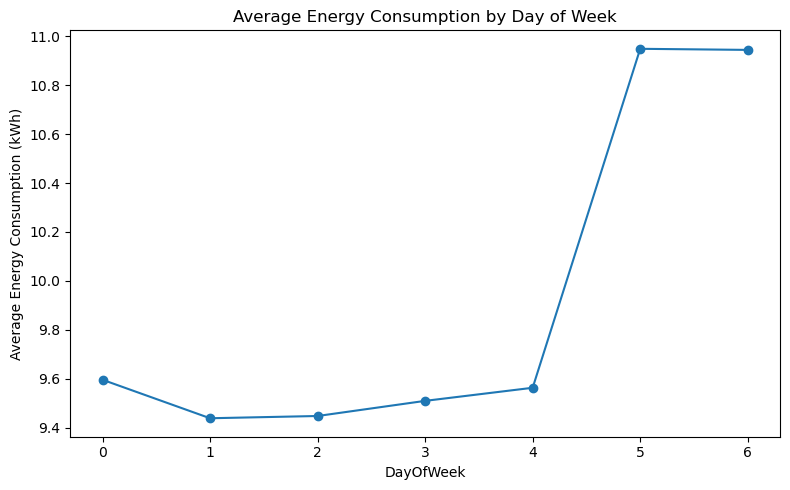

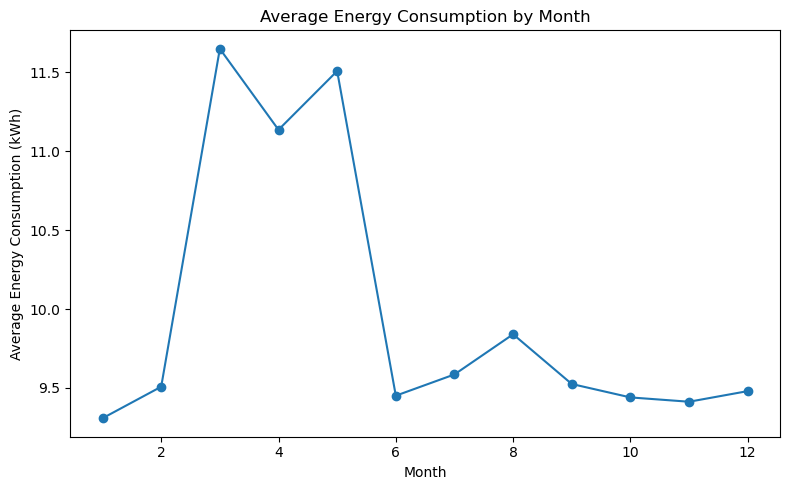

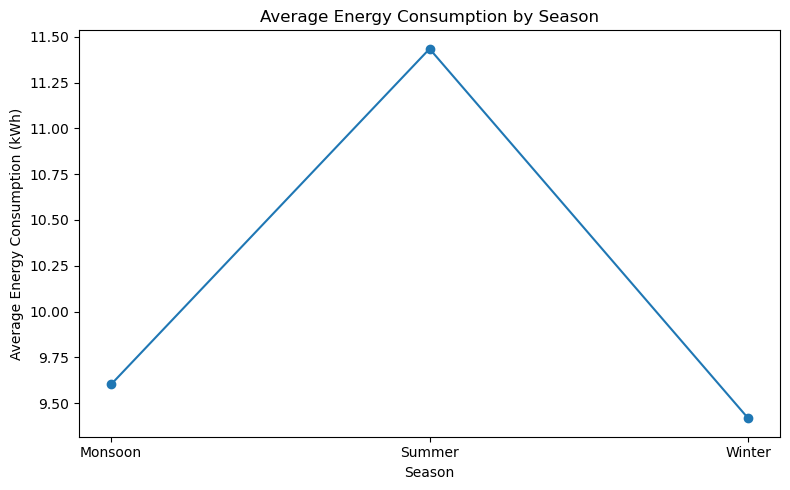

In [22]:
time_groups = {
    "Hour": "Average Energy Consumption by Hour",
    "DayOfWeek": "Average Energy Consumption by Day of Week",
    "Month": "Average Energy Consumption by Month",
    "Season": "Average Energy Consumption by Season"
}

for feature, title in time_groups.items():

    grouped = df.groupby(feature)["Energy_Consumption_kWh"].mean()

    plt.figure(figsize=(8, 5))
    plt.plot(grouped.index, grouped.values, marker="o")

    plt.title(title)
    plt.xlabel(feature)
    plt.ylabel("Average Energy Consumption (kWh)")

    plt.tight_layout()
    plt.show()

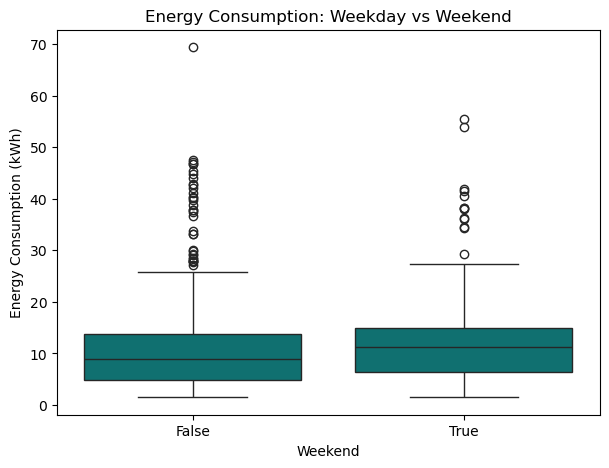

In [23]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="IsWeekend",
    y="Energy_Consumption_kWh",
    color="teal"
)

plt.title("Energy Consumption: Weekday vs Weekend")
plt.xlabel("Weekend")
plt.ylabel("Energy Consumption (kWh)")

plt.show()

### 3. Timestamp EDA in "Energy analysis"

### The primary target for forecasting is" energy consumption kwh"

In [24]:
df.columns

Index(['Timestamp', 'Energy_Consumption_kWh', 'Temperature_C',
       'Humidity_Percent', 'Occupancy', 'Electricity_Price_per_kWh',
       'Day_Type', 'Season', 'Weather_Condition', 'House_Type', 'HVAC_Status',
       'Water_Heater_Status', 'Anomaly', 'Hour', 'Day', 'Month', 'DayOfWeek',
       'DayName', 'IsWeekend'],
      dtype='object')

In [25]:
target = "Energy_Consumption_kWh"

In [26]:
#basic statistics
df[target].describe()

count    10000.000000
mean         9.917056
std          5.926119
min          1.500000
25%          5.180000
50%          9.640000
75%         14.130000
max         69.420000
Name: Energy_Consumption_kWh, dtype: float64

In [27]:
df[target].mean()

np.float64(9.917056)

In [28]:
df[target].median()

9.64

In [29]:
df[target].std()

5.926118940878033

In [30]:
df[target].skew() #right skewed: because it is positively skewed

np.float64(0.7954156367565931)

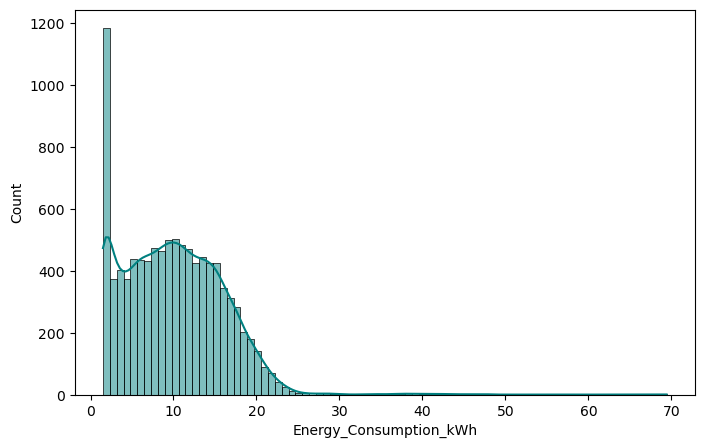

In [31]:
#energy distribution
plt.figure(figsize=(8,5))
sns.histplot(data=df, x= target, kde=True, color='Teal')
plt.show()

In [32]:
#HISTOGRAM - The distribution is right-skewed (positively skewed). 
#The bulk of the data points lie between approximately 2 and 20 kWh,
#with a long tail extending toward higher energy consumption values up to nearly 70 kWh.

<Axes: xlabel='Energy_Consumption_kWh'>

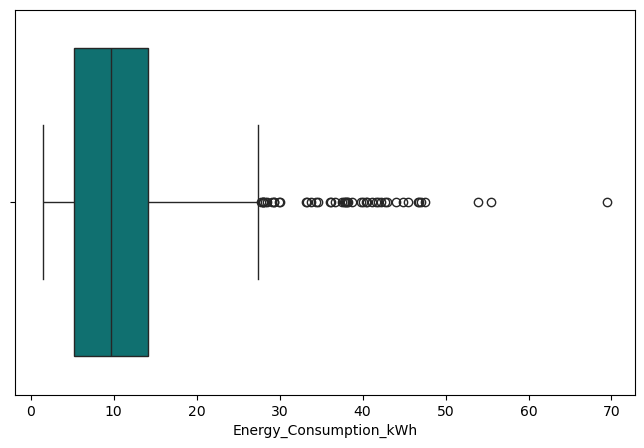

In [33]:
#energy boxplot
plt.figure(figsize=(8,5))
sns.boxplot(x=df[target], color="Teal")

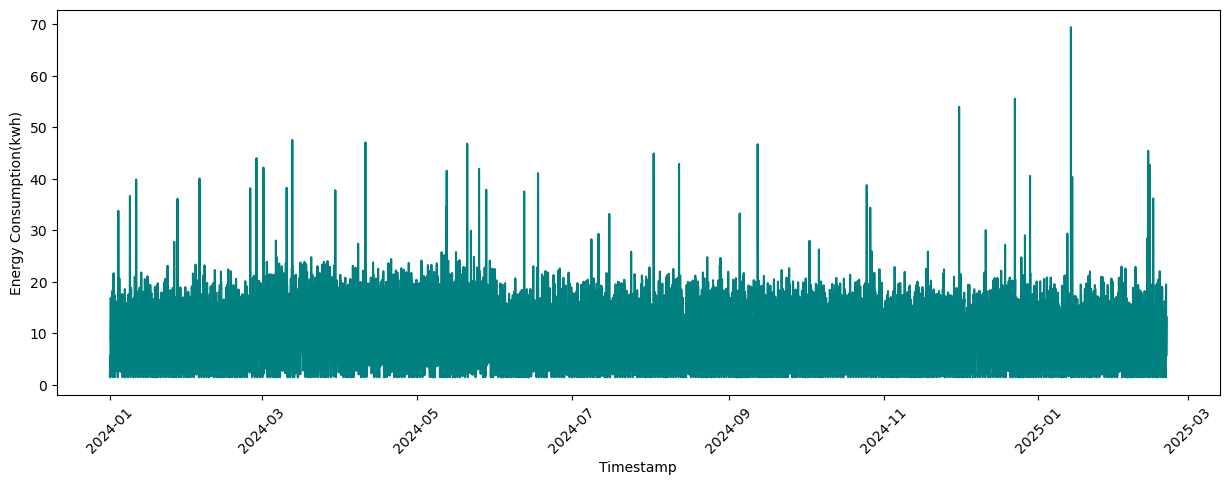

In [34]:
#energy consumption over time
plt.figure(figsize=(15,5))
plt.plot(df["Timestamp"],df[target],color='teal')
plt.xlabel("Timestamp")
plt.ylabel("Energy Consumption(kwh)")
plt.xticks(rotation=45)
plt.show()

### Timestamp EDA in Anomaly analysis

In [35]:
df.columns

Index(['Timestamp', 'Energy_Consumption_kWh', 'Temperature_C',
       'Humidity_Percent', 'Occupancy', 'Electricity_Price_per_kWh',
       'Day_Type', 'Season', 'Weather_Condition', 'House_Type', 'HVAC_Status',
       'Water_Heater_Status', 'Anomaly', 'Hour', 'Day', 'Month', 'DayOfWeek',
       'DayName', 'IsWeekend'],
      dtype='object')

In [36]:
target_column = "Anomaly"

In [37]:
df[target_column].value_counts()

Anomaly
0    9880
1     120
Name: count, dtype: int64

In [38]:
anomaly_percentage = df[target_column].value_counts(normalize=True)*100

In [39]:
anomaly_percentage

Anomaly
0    98.8
1     1.2
Name: proportion, dtype: float64

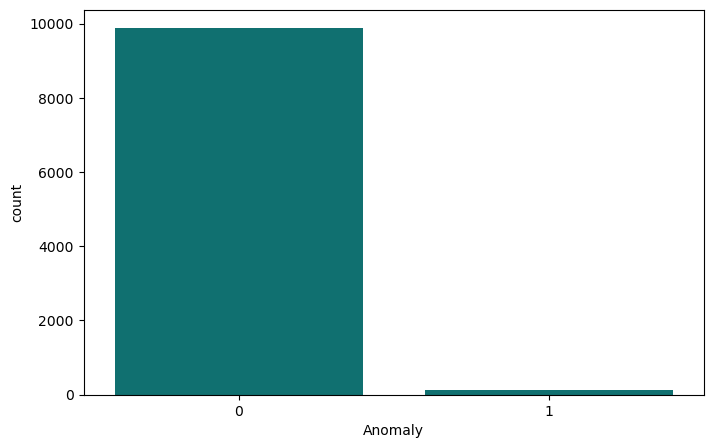

In [40]:
plt.figure(figsize=(8,5))
sns.countplot(data=df,x=target_column,color='teal')
plt.show()

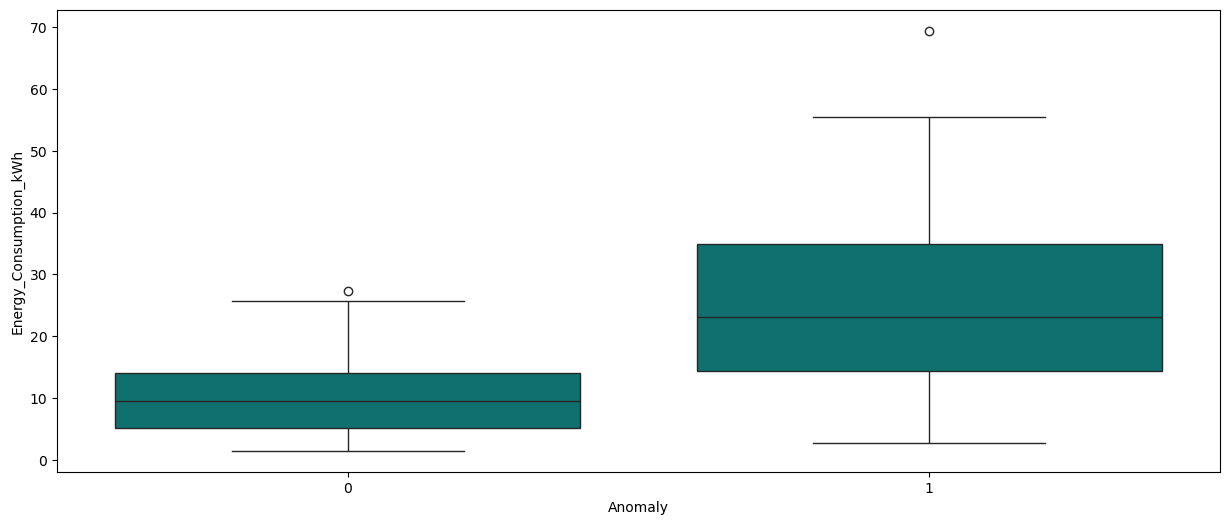

In [41]:
#normal vs anomaly
plt.figure(figsize=(15,6))
sns.boxplot(data=df,x=target_column,y=target,color='teal')
plt.show()

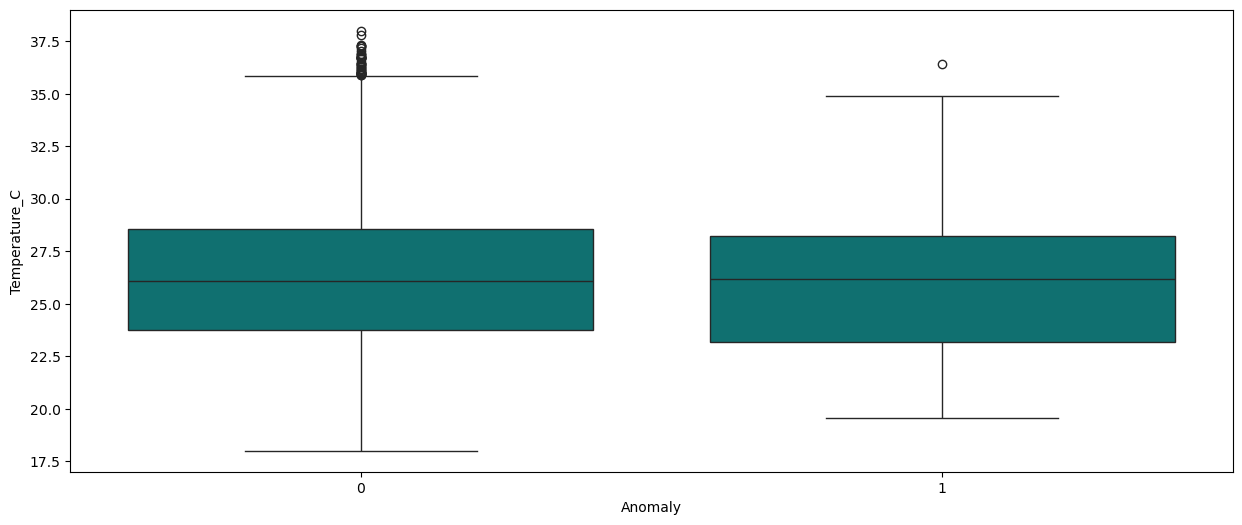

In [42]:
#Anomaly vs temperature
plt.figure(figsize=(15,6))
sns.boxplot(data=df,x=target_column,y="Temperature_C",color='teal')
plt.show()

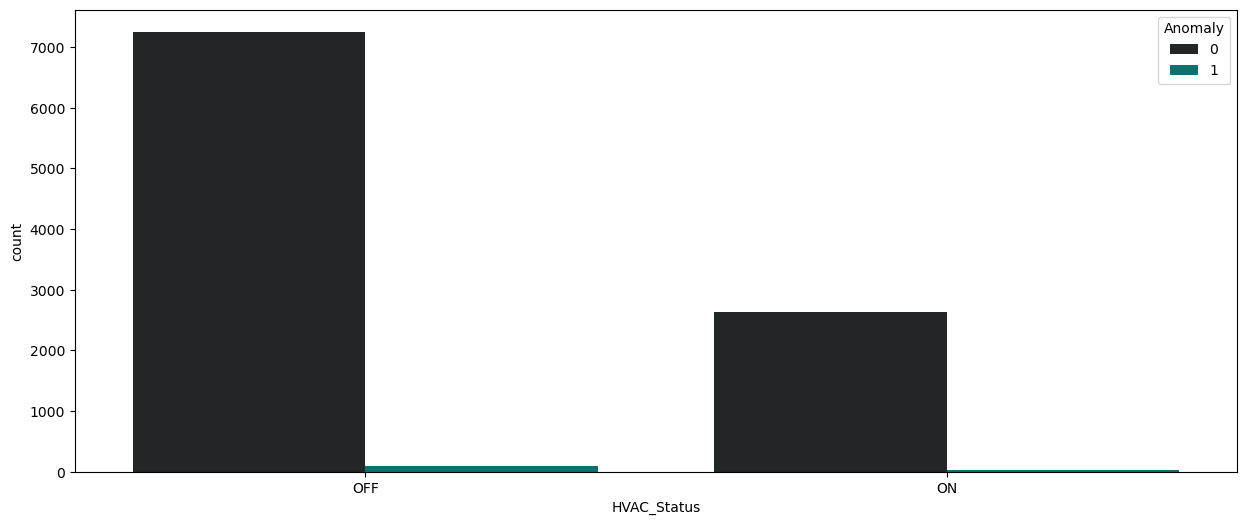

In [43]:
#Anomal vs HVAC
plt.figure(figsize=(15,6))
sns.countplot(data=df,x='HVAC_Status', hue="Anomaly", palette="dark:teal")
plt.show()

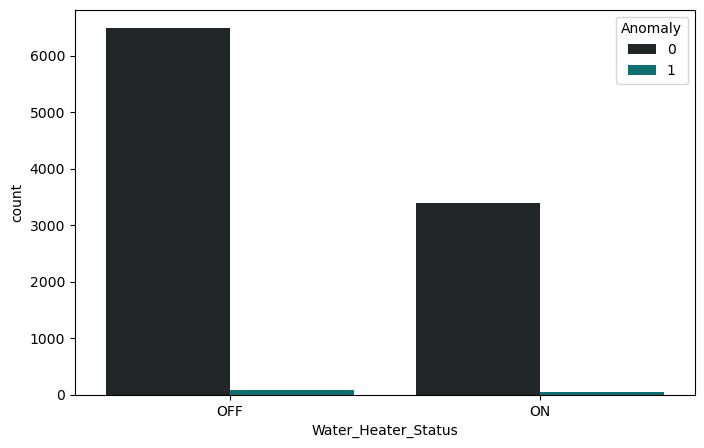

In [44]:
#anomaly vs waterheater
plt.figure(figsize=(8,5))
sns.countplot(data=df,x='Water_Heater_Status', hue="Anomaly", palette='dark:teal')
plt.show()

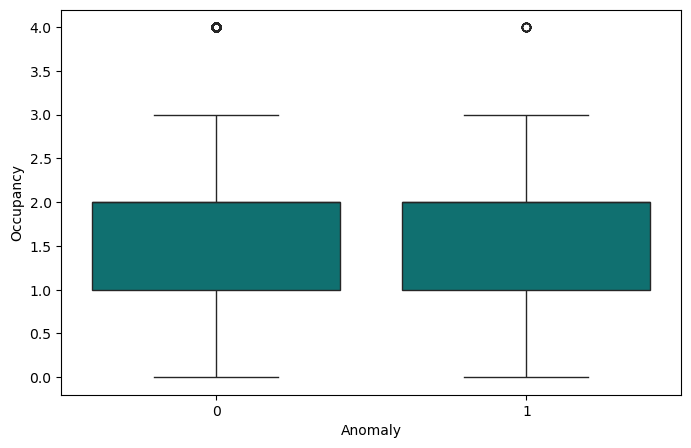

In [45]:
#anomaly vs occupancy
plt.figure(figsize=(8,5))
sns.boxplot(data=df,x=target_column,y="Occupancy",color='teal')
plt.show()

In [46]:
anomaly_by_hour = (
    df.groupby("Hour")["Anomaly"]
    .mean()
)

In [47]:
anomaly_by_hour

Hour
0     0.016787
1     0.002398
2     0.002398
3     0.019185
4     0.014388
5     0.011990
6     0.009592
7     0.009592
8     0.016787
9     0.019185
10    0.007194
11    0.021583
12    0.011990
13    0.014388
14    0.004796
15    0.011990
16    0.016827
17    0.014423
18    0.009615
19    0.014423
20    0.004808
21    0.012019
22    0.012019
23    0.009615
Name: Anomaly, dtype: float64

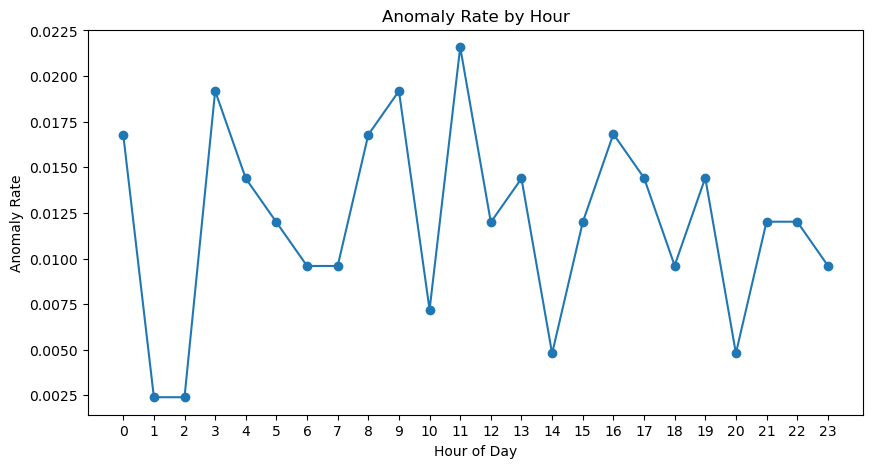

In [48]:
plt.figure(figsize=(10, 5))

plt.plot(
    anomaly_by_hour.index,
    anomaly_by_hour.values,
    marker="o"
)

plt.title("Anomaly Rate by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Anomaly Rate")

plt.xticks(range(24))

plt.show()

### 4. Feature Analysis

### Numerical Feature Analysis

In [49]:
df.columns

Index(['Timestamp', 'Energy_Consumption_kWh', 'Temperature_C',
       'Humidity_Percent', 'Occupancy', 'Electricity_Price_per_kWh',
       'Day_Type', 'Season', 'Weather_Condition', 'House_Type', 'HVAC_Status',
       'Water_Heater_Status', 'Anomaly', 'Hour', 'Day', 'Month', 'DayOfWeek',
       'DayName', 'IsWeekend'],
      dtype='object')

In [50]:
numerical_features = ["Temperature_C","Humidity_Percent","Occupancy","Electricity_Price_per_kWh"]

In [51]:
numerical_features

['Temperature_C', 'Humidity_Percent', 'Occupancy', 'Electricity_Price_per_kWh']

In [52]:
df[numerical_features].describe()

,Temperature_C,Humidity_Percent,Occupancy,Electricity_Price_per_kWh
count,10000.000000,10000.000000,10000.000000,10000.000000
mean,26.427605,76.846589,1.663700,4.773437
std,3.576525,9.949923,1.217025,0.795498
min,18.000000,49.950000,0.000000,3.350000
25%,23.730000,69.060000,1.000000,3.930000
50%,26.110000,76.300000,2.000000,4.860000
75%,28.580000,83.322500,2.000000,5.140000
max,38.000000,98.000000,4.000000,6.490000


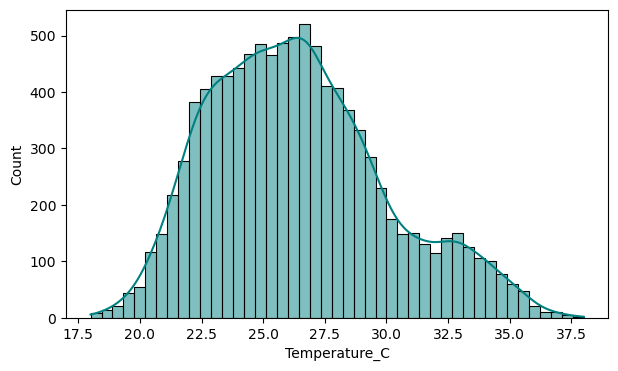

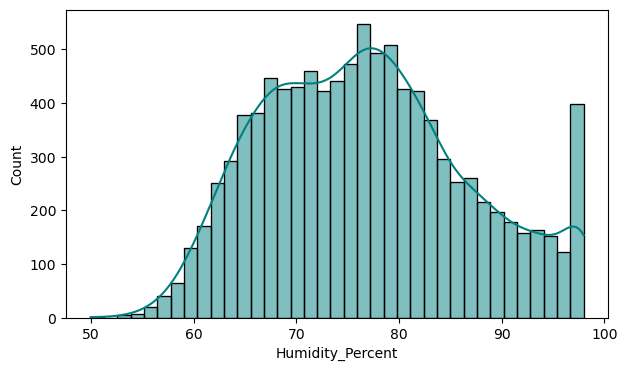

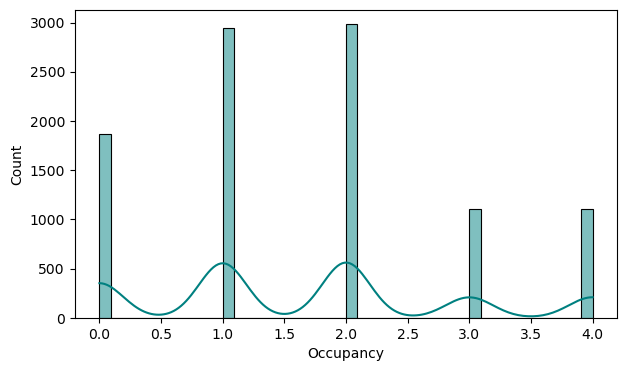

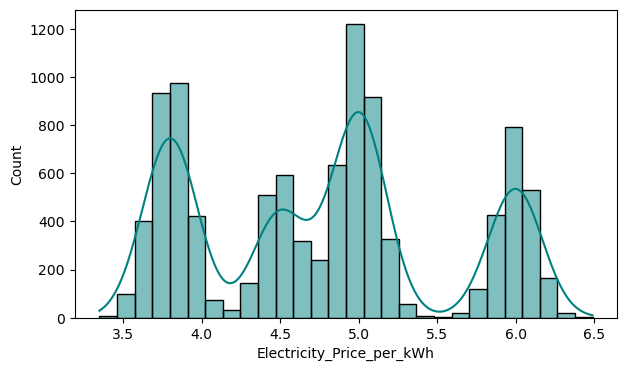

In [53]:
#Numerical distributions
for column in numerical_features:
     plt.figure(figsize=(7,4))
     sns.histplot(data=df,x=column,kde=True,color='teal')
     plt.show()

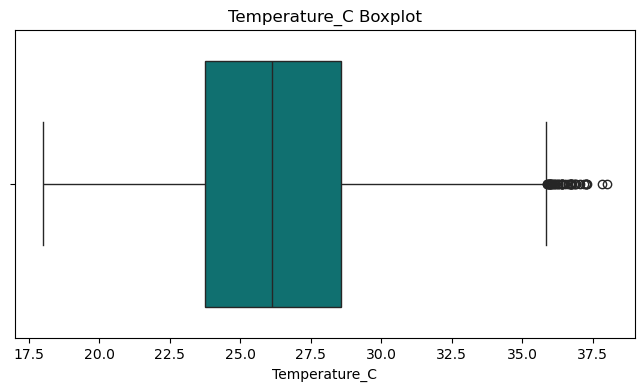

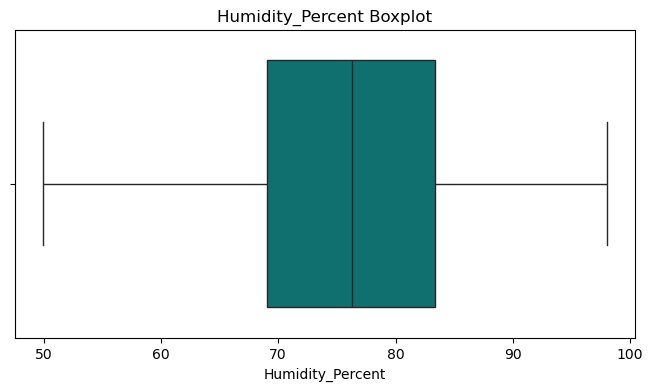

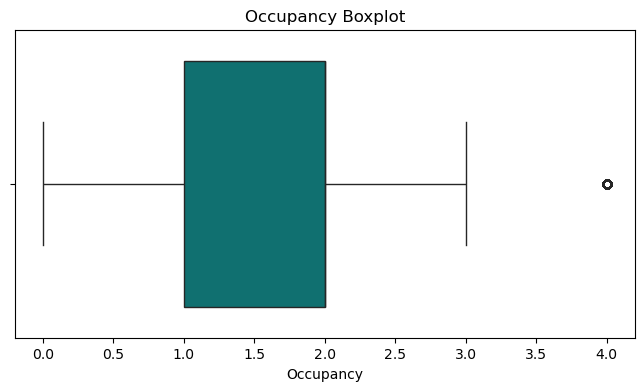

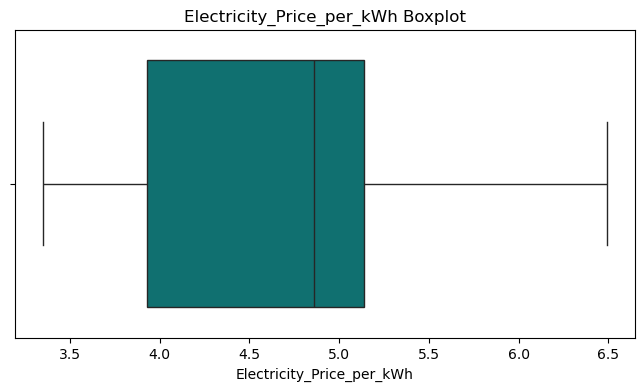

In [54]:
#numerical boxplots
for column in numerical_features:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        x=df[column],color='teal'
    )

    plt.title(f"{column} Boxplot")

    plt.show()

### Categorical feature Analysis

In [55]:
categorical_features = ['Day_Type', 'Season', 'Weather_Condition', 'House_Type', 'HVAC_Status',
       'Water_Heater_Status']

In [56]:
df.dtypes

Timestamp                    datetime64[ns]
Energy_Consumption_kWh              float64
Temperature_C                       float64
Humidity_Percent                    float64
Occupancy                             int64
Electricity_Price_per_kWh           float64
Day_Type                             object
Season                               object
Weather_Condition                    object
House_Type                           object
HVAC_Status                          object
Water_Heater_Status                  object
Anomaly                               int64
Hour                                  int32
Day                                   int32
Month                                 int32
DayOfWeek                             int32
DayName                              object
IsWeekend                              bool
dtype: object

In [57]:
categorical_features

['Day_Type',
 'Season',
 'Weather_Condition',
 'House_Type',
 'HVAC_Status',
 'Water_Heater_Status']

In [58]:
df[categorical_features].value_counts().sum()

np.int64(10000)

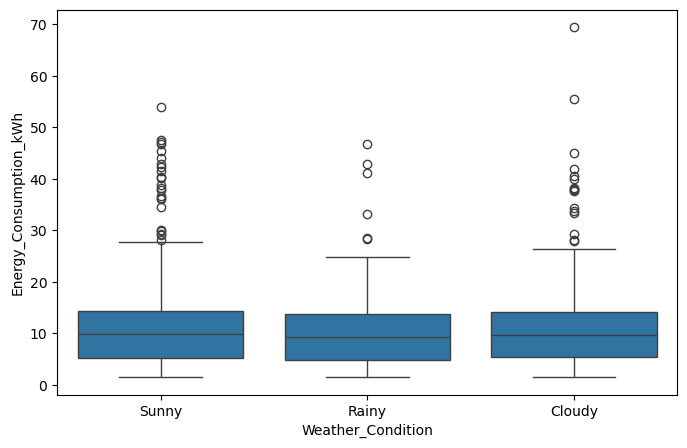

In [59]:
#categorical visualization
plt.figure(figsize=(8,5))
sns.boxplot(data=df,x='Weather_Condition',y='Energy_Consumption_kWh')
plt.show()


Day_Type
Day_Type
Weekday    7168
Weekend    2832
Name: count, dtype: int64


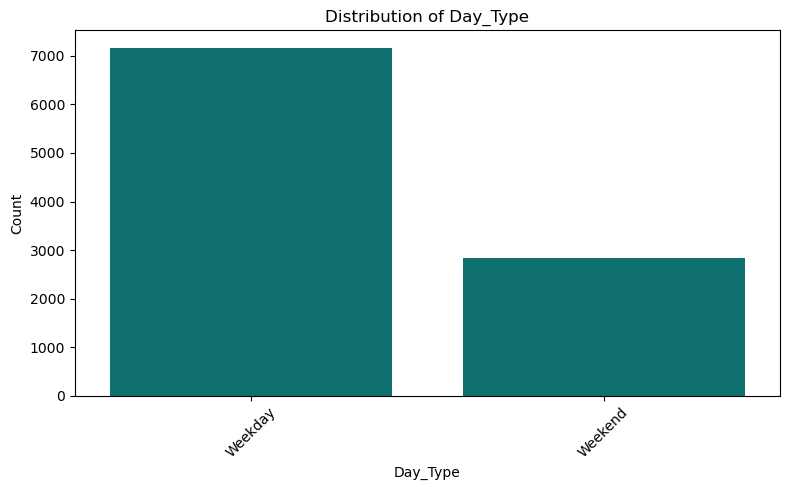


Season
Season
Winter     4864
Monsoon    2928
Summer     2208
Name: count, dtype: int64


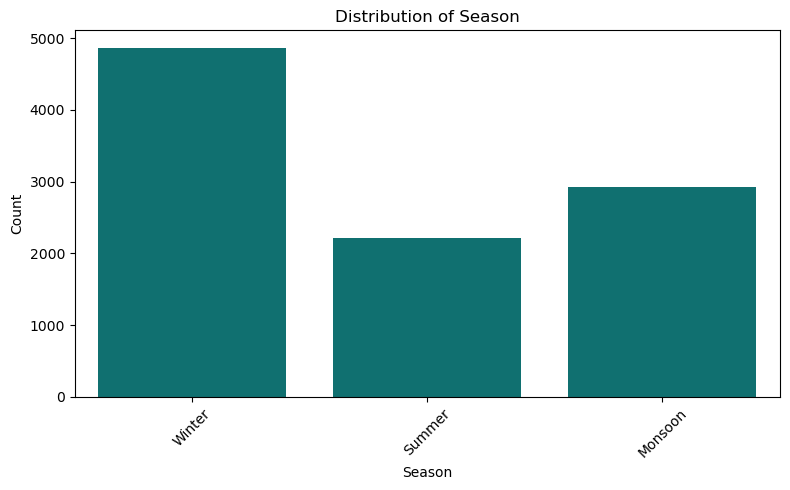


Weather_Condition
Weather_Condition
Sunny     5079
Rainy     2502
Cloudy    2419
Name: count, dtype: int64


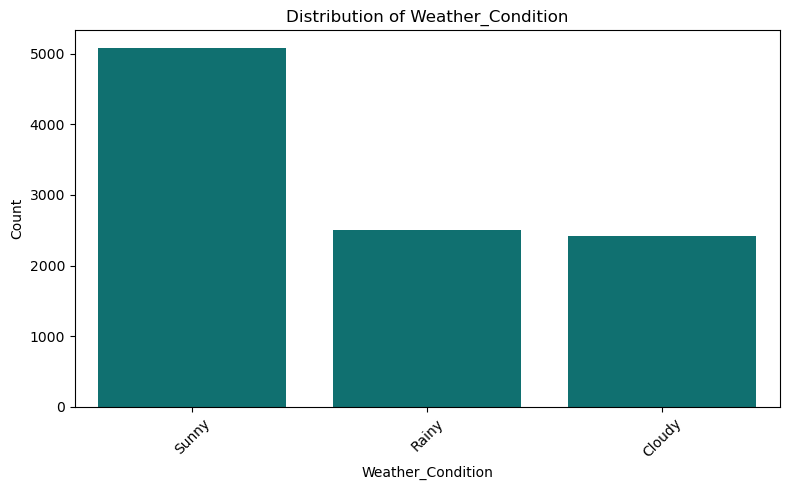


House_Type
House_Type
Independent House    4546
Apartment            4433
Villa                1021
Name: count, dtype: int64


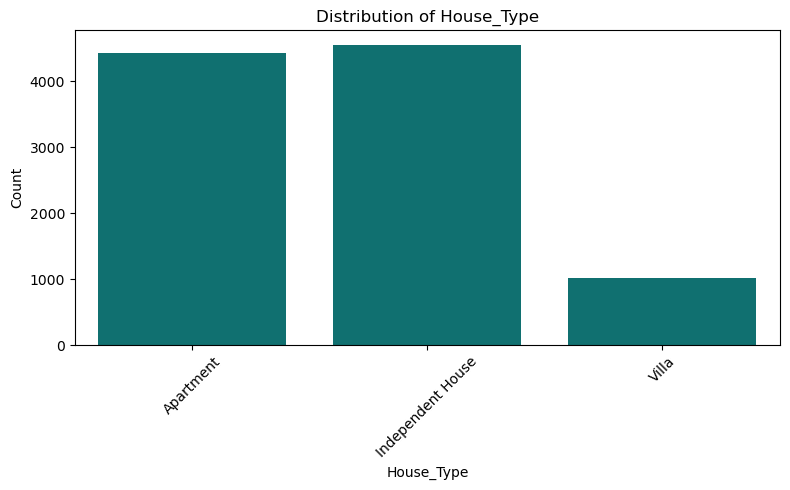


HVAC_Status
HVAC_Status
OFF    7345
ON     2655
Name: count, dtype: int64


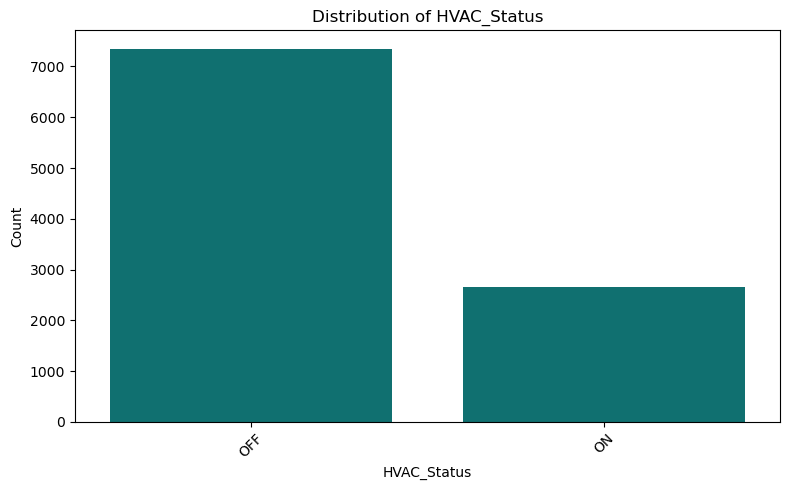


Water_Heater_Status
Water_Heater_Status
OFF    6567
ON     3433
Name: count, dtype: int64


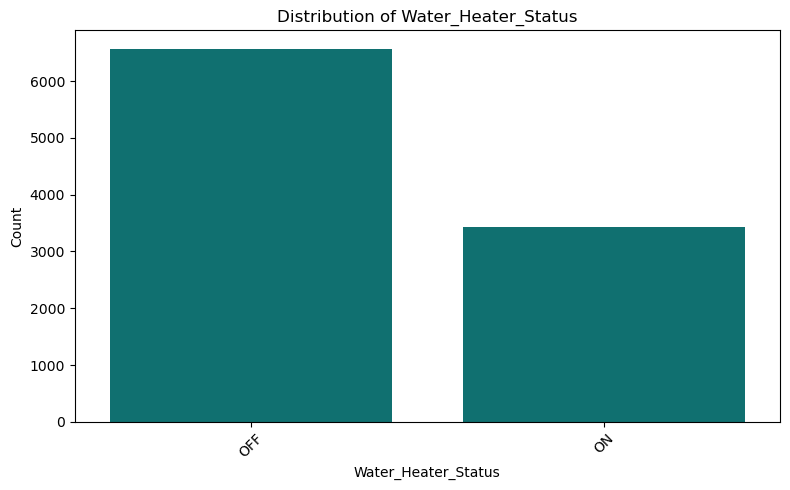

In [60]:
for feature in categorical_features:

    print(f"\n{feature}")
    print(df[feature].value_counts())

    plt.figure(figsize=(8, 5))

    sns.countplot(
        data=df,
        x=feature,
        color="teal"
    )

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Count")

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### 5. Energy Relationships

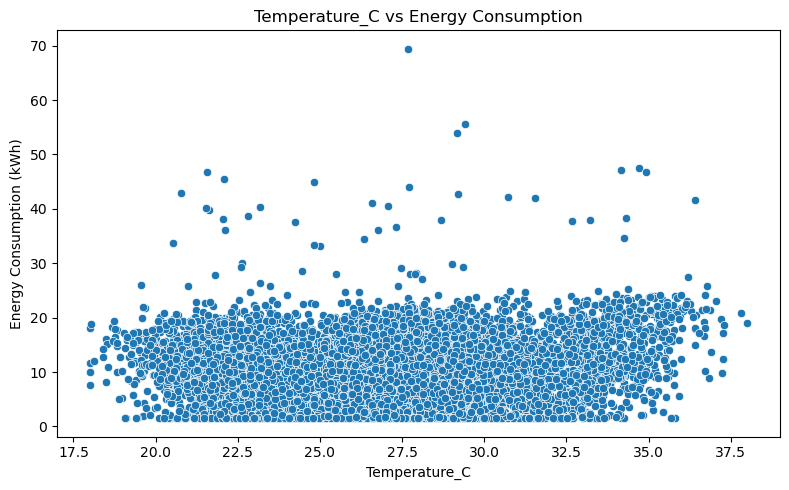

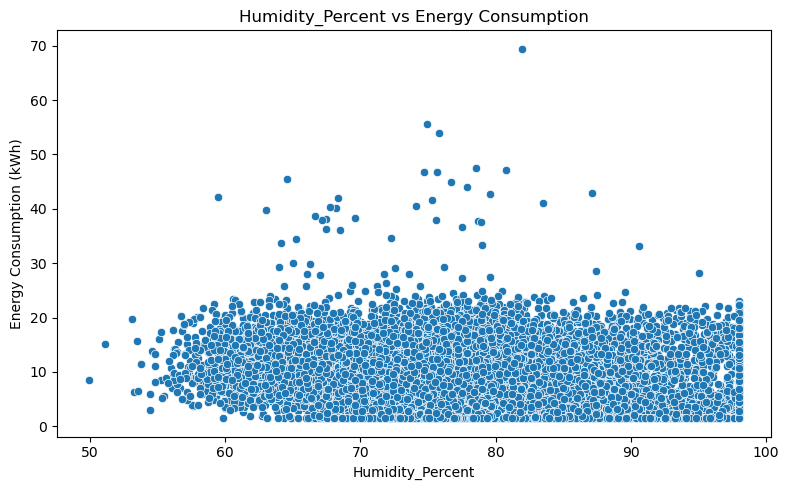

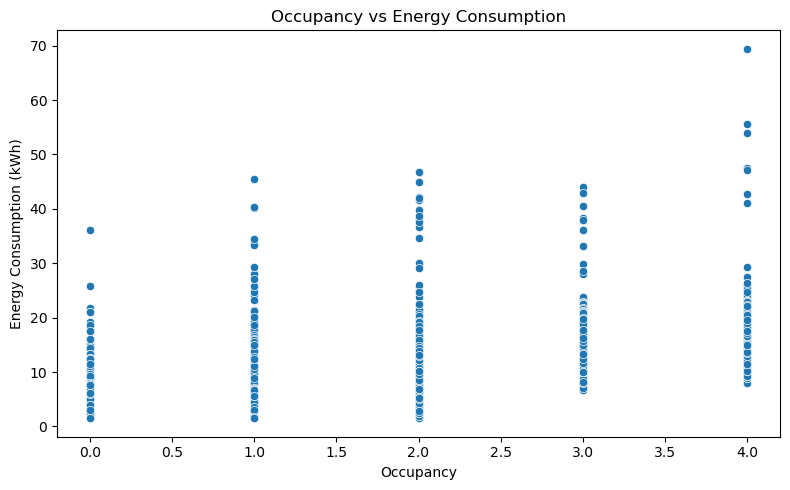

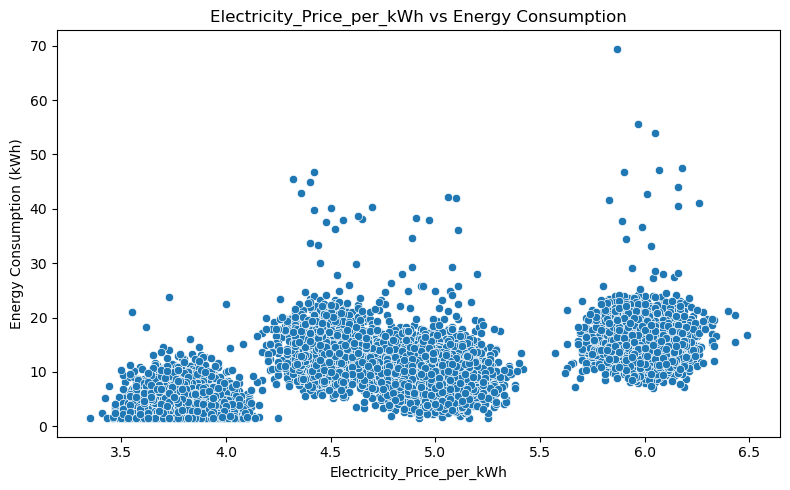

In [61]:
#for numerical features
numerical_features = [
    "Temperature_C",
    "Humidity_Percent",
    "Occupancy",
    "Electricity_Price_per_kWh"
]

for feature in numerical_features:

    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        data=df,
        x=feature,
        y="Energy_Consumption_kWh"
    )

    plt.title(
        f"{feature} vs Energy Consumption"
    )

    plt.xlabel(feature)
    plt.ylabel("Energy Consumption (kWh)")

    plt.tight_layout()
    plt.show()

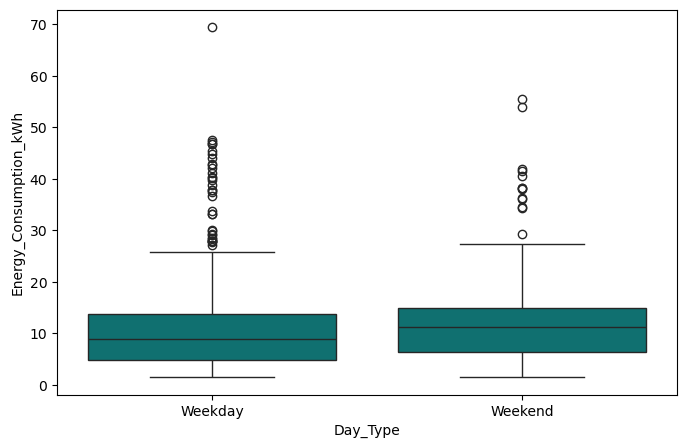

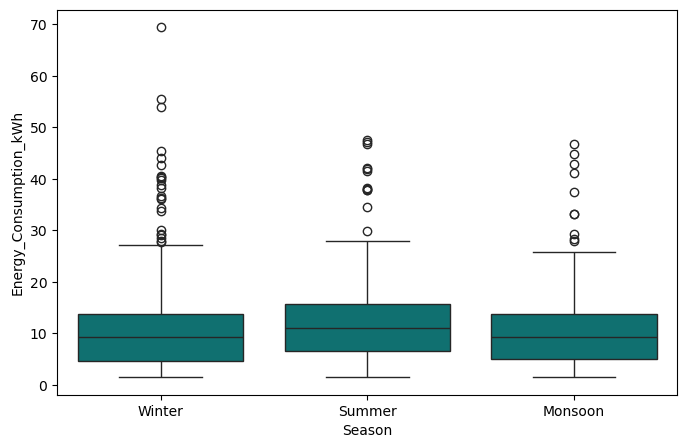

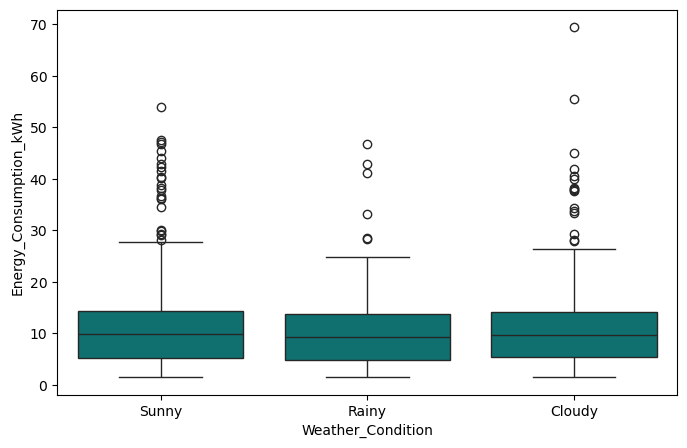

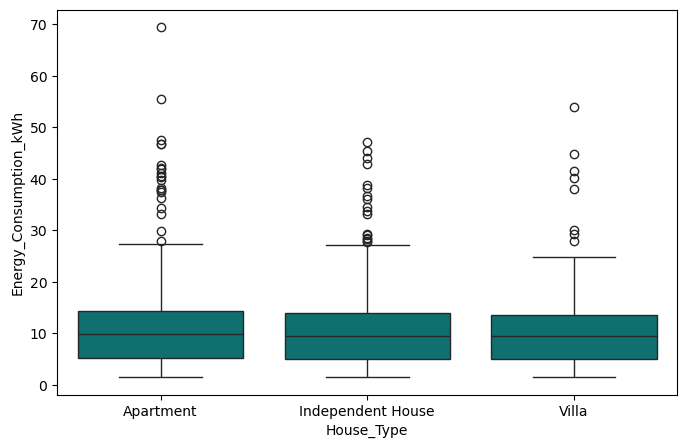

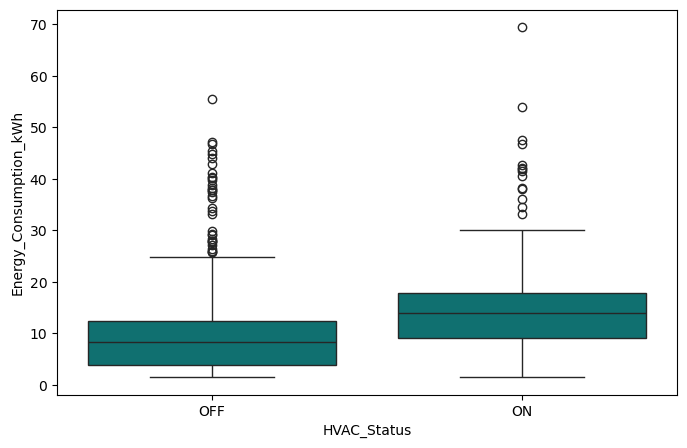

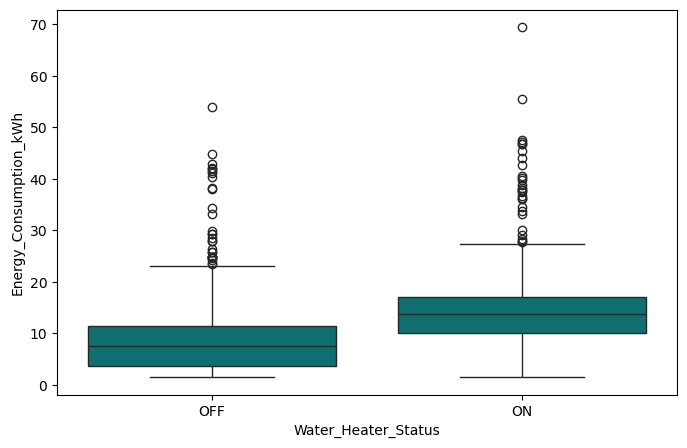

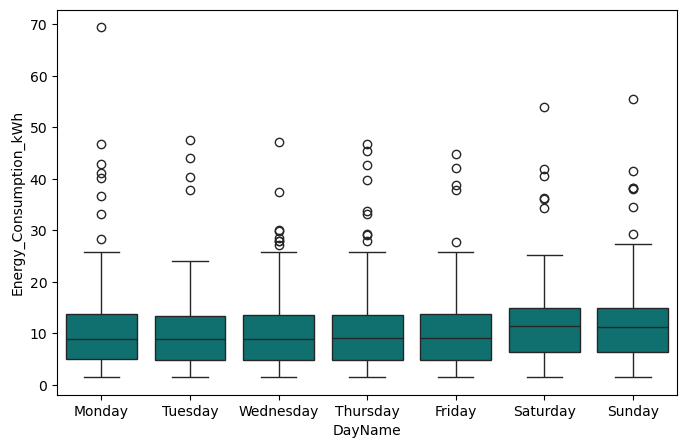

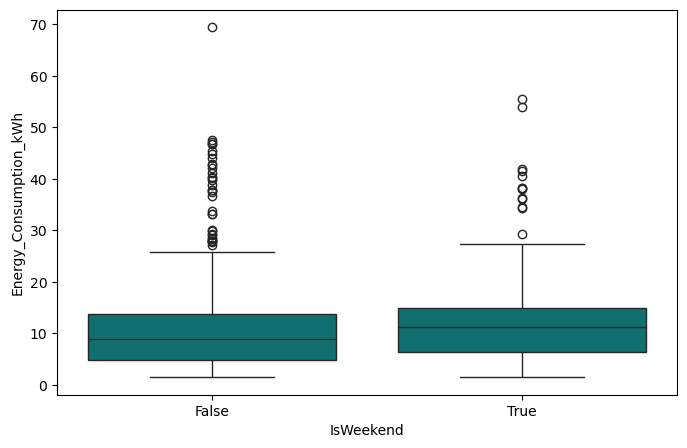

In [62]:
#for categorical features
# Defined as a dictionary with "boxplot" as the key
relationship_features = {
    "boxplot": ['Day_Type', 'Season', 'Weather_Condition', 'House_Type', 'HVAC_Status', 'Water_Heater_Status', 'DayName', 'IsWeekend']
}

for f in relationship_features["boxplot"]:  # Now this works because it's a dictionary
    plt.figure(figsize=(8, 5))
    sns.boxplot(
        data=df,
        x=f,
        y=target,
        color='teal'
    )
    plt.show()

### 6. Correlation Analysis

In [63]:
df.columns

Index(['Timestamp', 'Energy_Consumption_kWh', 'Temperature_C',
       'Humidity_Percent', 'Occupancy', 'Electricity_Price_per_kWh',
       'Day_Type', 'Season', 'Weather_Condition', 'House_Type', 'HVAC_Status',
       'Water_Heater_Status', 'Anomaly', 'Hour', 'Day', 'Month', 'DayOfWeek',
       'DayName', 'IsWeekend'],
      dtype='object')

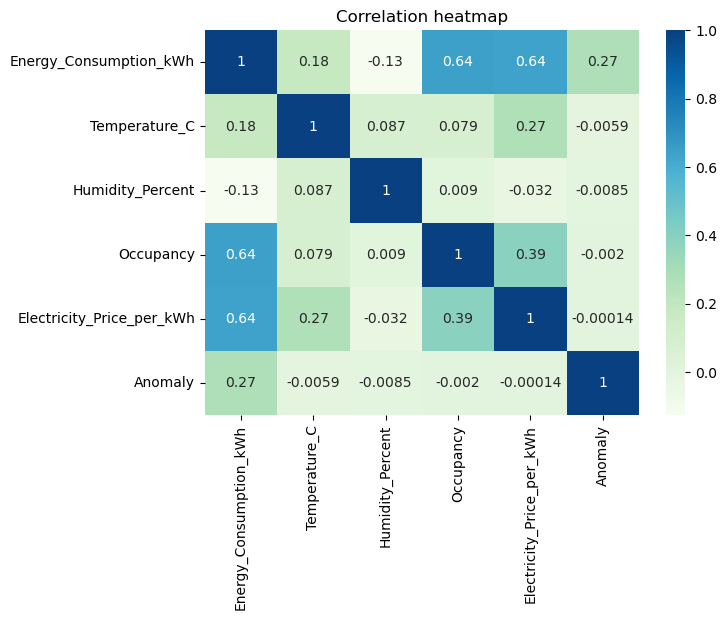

In [64]:
correlation_columns = ["Energy_Consumption_kWh","Temperature_C","Humidity_Percent","Occupancy","Electricity_Price_per_kWh","Anomaly"]
correlation_matrix = df[correlation_columns].corr()
plt.figure(figsize=(7,5))
sns.heatmap(correlation_matrix, annot=True, cmap="GnBu")
plt.title("Correlation heatmap")
plt.show()

In [65]:
#The correlation analysis shows that occupancy and electricity price have the strongest positive associations with energy consumption, with correlation coefficients of 0.64 each. Temperature shows a weak positive relationship, while humidity has a weak negative relationship. For anomaly detection, energy consumption has a weak positive correlation of 0.27 with the anomaly label, whereas the other numerical features show correlations close to zero. These results indicate that anomalies cannot be explained by a single numerical feature alone and support the need for a model capable of learning more complex patterns."

### 7. Optimization EDA

### The optimization goal is: understand when energy is consumed,what it costs,and which appliances are assosciated with higher consumpton so that later the system can recommend more efficient operation

### Electricity price analysis

In [66]:
df.columns

Index(['Timestamp', 'Energy_Consumption_kWh', 'Temperature_C',
       'Humidity_Percent', 'Occupancy', 'Electricity_Price_per_kWh',
       'Day_Type', 'Season', 'Weather_Condition', 'House_Type', 'HVAC_Status',
       'Water_Heater_Status', 'Anomaly', 'Hour', 'Day', 'Month', 'DayOfWeek',
       'DayName', 'IsWeekend'],
      dtype='object')

In [67]:
df["Electricity_Price_per_kWh"].describe()

count    10000.000000
mean         4.773437
std          0.795498
min          3.350000
25%          3.930000
50%          4.860000
75%          5.140000
max          6.490000
Name: Electricity_Price_per_kWh, dtype: float64

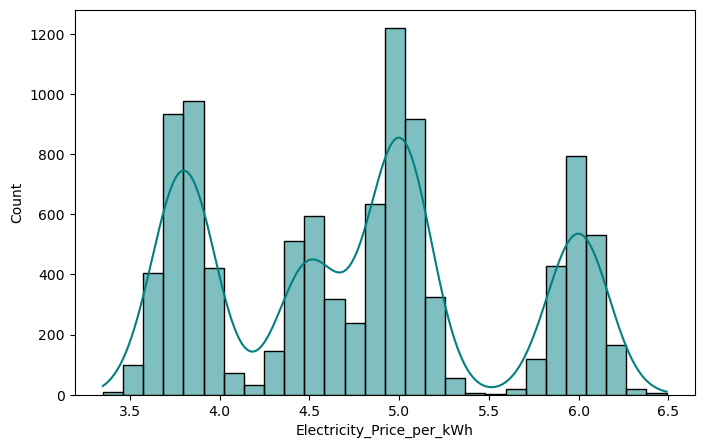

In [68]:
#price disribution
plt.figure(figsize=(8,5))
sns.histplot(data=df, x="Electricity_Price_per_kWh", kde=True, color="Teal")
plt.show()

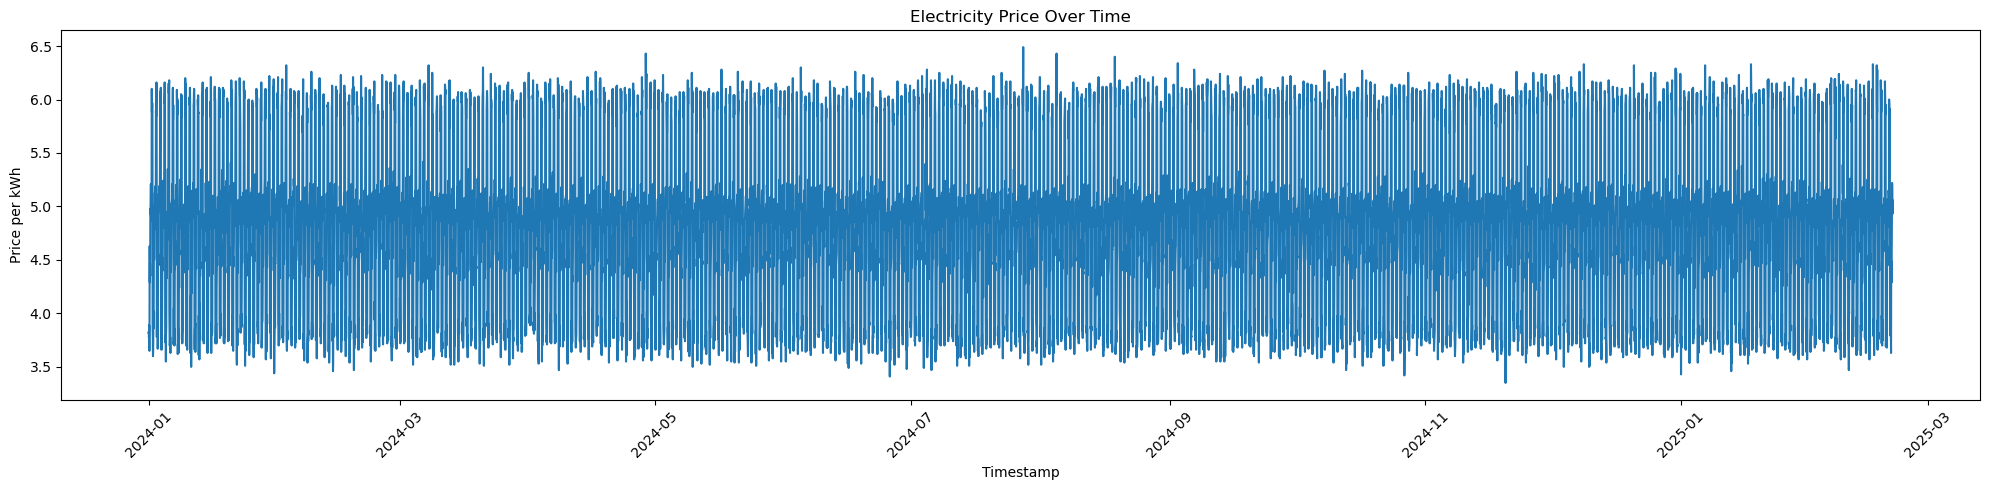

In [69]:
#electricity price over time
plt.figure(figsize=(20, 5))

plt.plot(
    df["Timestamp"],
    df["Electricity_Price_per_kWh"]
)

plt.title("Electricity Price Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Price per kWh")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Energy cost analysis

In [70]:
#checking energy cost
df["Energy_Cost"] = (
    df["Energy_Consumption_kWh"]
    *
    df["Electricity_Price_per_kWh"]
)

In [71]:
df[
    [
        "Energy_Consumption_kWh",
        "Electricity_Price_per_kWh",
        "Energy_Cost"
    ]
].head()

,Energy_Consumption_kWh,Electricity_Price_per_kWh,Energy_Cost
0,2.32,3.82,8.8624
1,1.50,3.83,5.7450
2,5.60,3.77,21.1120
3,1.50,3.89,5.8350
4,1.63,3.66,5.9658


In [72]:
#energy cost statistics
df["Energy_Cost"].describe()

count    10000.000000
mean        50.333726
std         34.228724
min          5.025000
25%         21.662400
50%         46.912200
75%         72.599825
max        407.495400
Name: Energy_Cost, dtype: float64

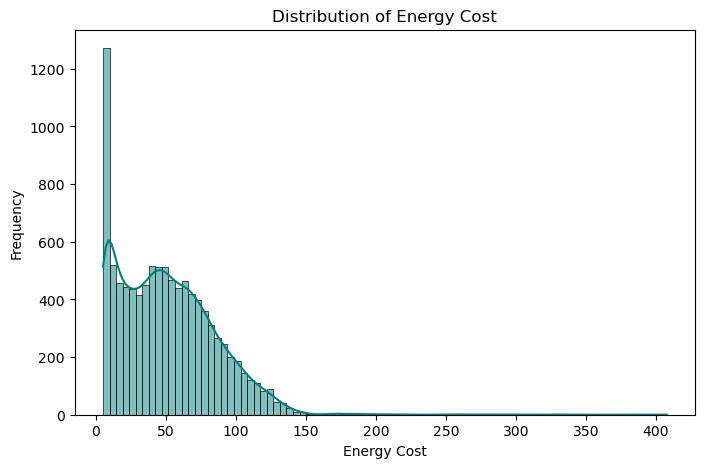

In [73]:
#energy cost distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Energy_Cost",
    kde=True,
    color='teal'
)

plt.title("Distribution of Energy Cost")
plt.xlabel("Energy Cost")
plt.ylabel("Frequency")

plt.show()

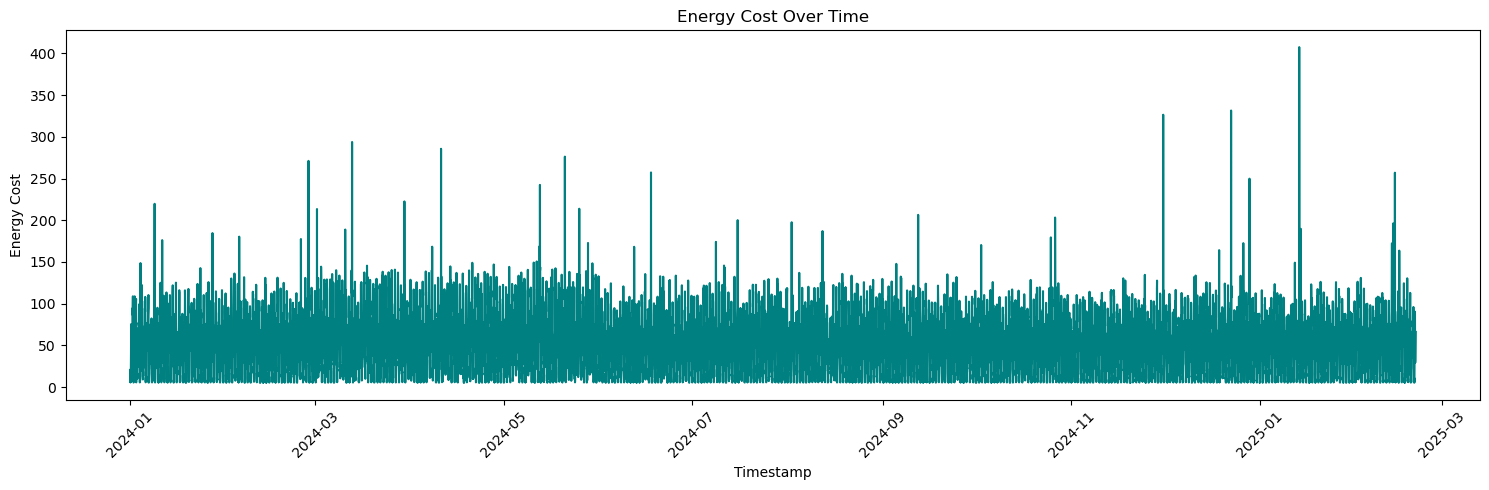

In [74]:
#energy cost overtime
plt.figure(figsize=(15, 5))

plt.plot(
    df["Timestamp"],
    df["Energy_Cost"],
    color="teal"
)

plt.title("Energy Cost Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Energy Cost")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Appliance Analysis

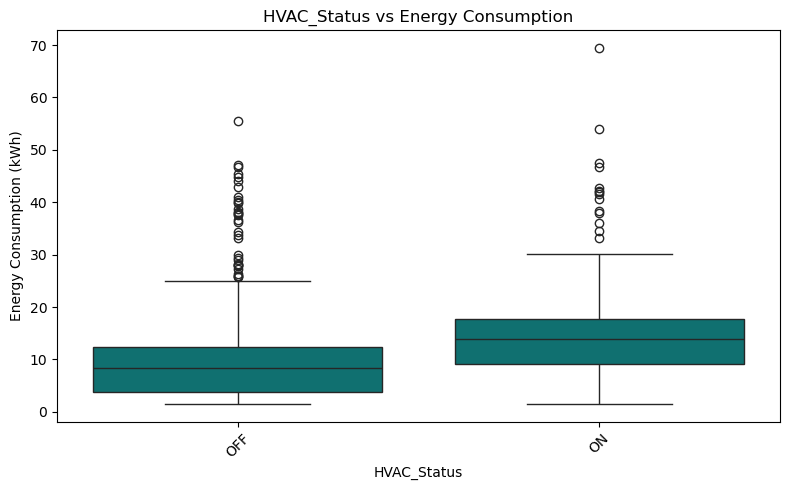

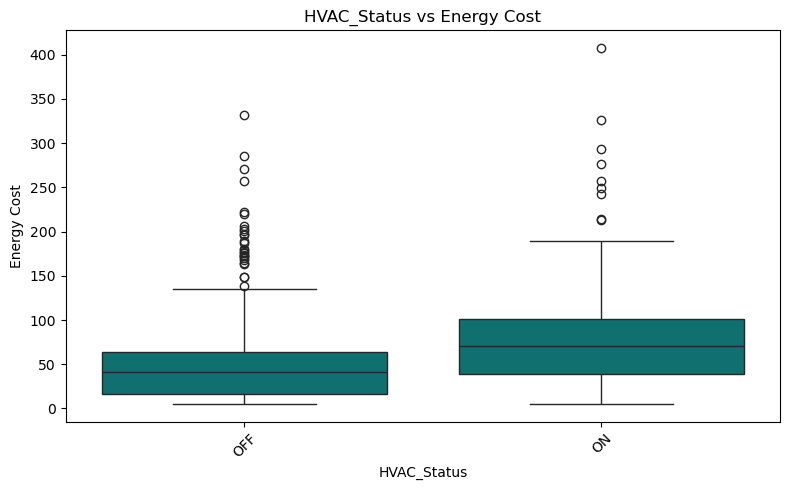

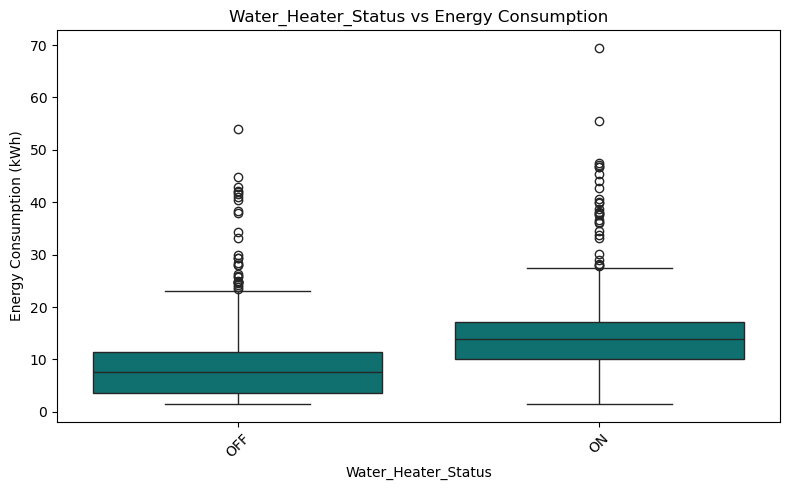

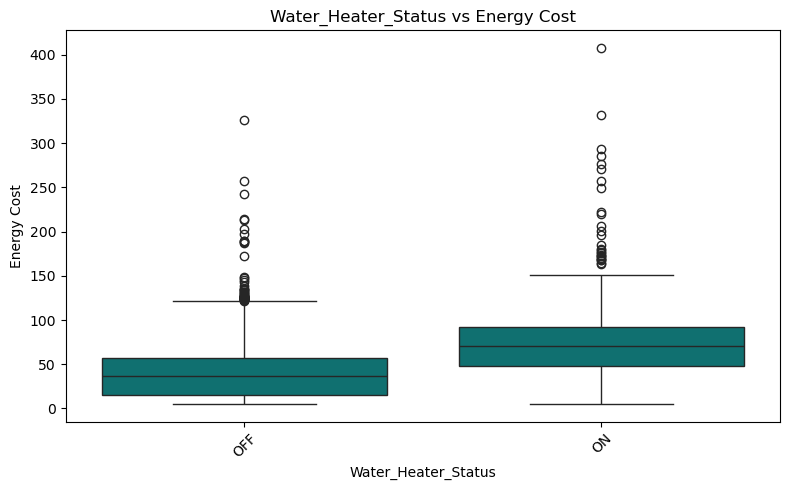

In [75]:
appliance_features = [
    "HVAC_Status",
    "Water_Heater_Status"
]

for appliance in appliance_features:

    # Energy Consumption
    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x=appliance,
        y="Energy_Consumption_kWh",
        color='teal'
    )

    plt.title(f"{appliance} vs Energy Consumption")
    plt.xlabel(appliance)
    plt.ylabel("Energy Consumption (kWh)")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

    # Energy Cost
    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x=appliance,
        y="Energy_Cost",
        color='teal'
    )

    plt.title(f"{appliance} vs Energy Cost")
    plt.xlabel(appliance)
    plt.ylabel("Energy Cost")

    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

In [76]:
#high-cost period analysis
df.nlargest(
    20,
    "Energy_Cost"
)[
    [
        "Timestamp",
        "Energy_Consumption_kWh",
        "Electricity_Price_per_kWh",
        "Energy_Cost",
        "Occupancy",
        "HVAC_Status",
        "Water_Heater_Status",
        "Season"
    ]
]

,Timestamp,Energy_Consumption_kWh,Electricity_Price_per_kWh,Energy_Cost,Occupancy,HVAC_Status,Water_Heater_Status,Season
9093,2025-01-13 21:00:00,69.42,5.87,407.4954,4,ON,ON,Winter
8563,2024-12-22 19:00:00,55.53,5.97,331.5141,4,OFF,ON,Winter
8035,2024-11-30 19:00:00,53.96,6.05,326.4580,4,ON,OFF,Winter
1726,2024-03-12 22:00:00,47.54,6.18,293.7972,4,ON,ON,Summer
2418,2024-04-10 18:00:00,47.06,6.07,285.6542,4,OFF,ON,Summer
3381,2024-05-20 21:00:00,46.82,5.90,276.2380,2,ON,ON,Summer
1387,2024-02-27 19:00:00,44.02,6.16,271.1632,3,OFF,ON,Winter
4051,2024-06-17 19:00:00,41.10,6.26,257.2860,4,OFF,OFF,Monsoon
9837,2025-02-13 21:00:00,42.76,6.01,256.9876,4,ON,ON,Winter
8706,2024-12-28 18:00:00,40.56,6.16,249.8496,3,ON,ON,Winter


In [77]:
#high consumption period analysis
df.nlargest(
    20,
    "Energy_Consumption_kWh"
)[
    [
        "Timestamp",
        "Energy_Consumption_kWh",
        "Electricity_Price_per_kWh",
        "Occupancy",
        "HVAC_Status",
        "Water_Heater_Status",
        "Season",
        "Anomaly"
    ]
]

,Timestamp,Energy_Consumption_kWh,Electricity_Price_per_kWh,Occupancy,HVAC_Status,Water_Heater_Status,Season,Anomaly
9093,2025-01-13 21:00:00,69.42,5.87,4,ON,ON,Winter,1
8563,2024-12-22 19:00:00,55.53,5.97,4,OFF,ON,Winter,1
8035,2024-11-30 19:00:00,53.96,6.05,4,ON,OFF,Winter,1
1726,2024-03-12 22:00:00,47.54,6.18,4,ON,ON,Summer,1
2418,2024-04-10 18:00:00,47.06,6.07,4,OFF,ON,Summer,1
3381,2024-05-20 21:00:00,46.82,5.90,2,ON,ON,Summer,1
6129,2024-09-12 09:00:00,46.71,4.42,2,OFF,ON,Monsoon,1
9824,2025-02-13 08:00:00,45.43,4.32,1,OFF,ON,Winter,1
5145,2024-08-02 09:00:00,44.91,4.40,2,OFF,OFF,Monsoon,1
1387,2024-02-27 19:00:00,44.02,6.16,3,OFF,ON,Winter,1


### 8.Multivariable Analysis

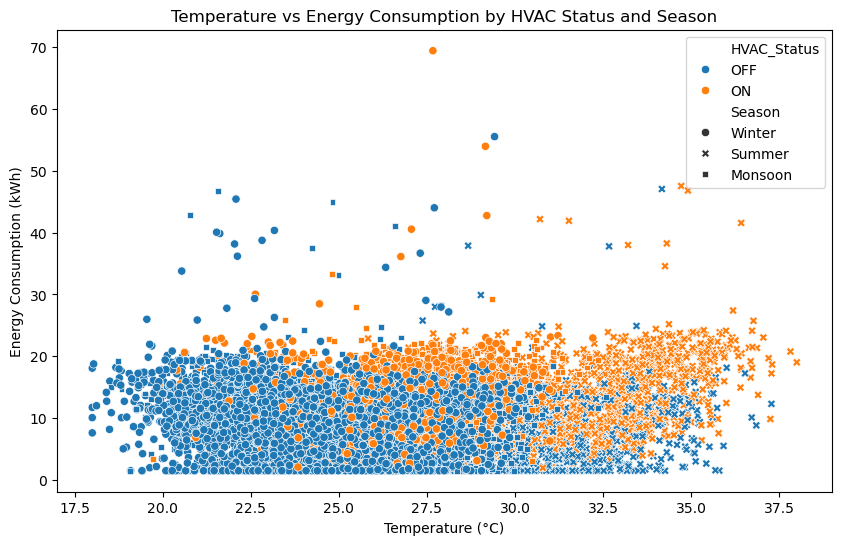

In [78]:
#temperature + HVAC + Season
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Temperature_C",
    y=target,
    hue="HVAC_Status",
    style="Season"
)

plt.title(
    "Temperature vs Energy Consumption by HVAC Status and Season"
)

plt.xlabel("Temperature (°C)")
plt.ylabel("Energy Consumption (kWh)")

plt.show()

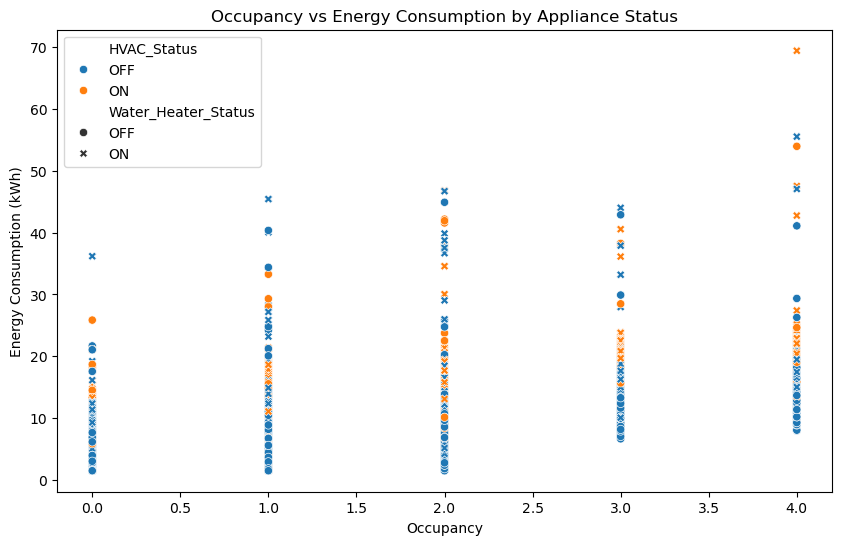

In [79]:
#occupancy + HVAC + waterheater
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Occupancy",
    y=target,
    hue="HVAC_Status",
    style="Water_Heater_Status"
)

plt.title(
    "Occupancy vs Energy Consumption by Appliance Status"
)

plt.xlabel("Occupancy")
plt.ylabel("Energy Consumption (kWh)")

plt.show()

### 9.Outlier Analysis

In [80]:
outlier_columns = [
    "Energy_Consumption_kWh",
    "Temperature_C",
    "Humidity_Percent",
    "Occupancy",
    "Electricity_Price_per_kWh"
]

### IQR method

In [81]:
for column in outlier_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(
        f"{column}: {len(outliers)} outliers"
    )

Energy_Consumption_kWh: 46 outliers
Temperature_C: 44 outliers
Humidity_Percent: 0 outliers
Occupancy: 1107 outliers
Electricity_Price_per_kWh: 0 outliers


In [ ]:
df.to_csv('energy_processed.csv', index=False)

NameError: name 'energy_consumption' is not defined

### EDA INSIGHTS

### Dataset Quality
The dataset contains 10,000 hourly observations with no missing values,
duplicate rows, duplicate timestamps, or missing hourly timestamps.

### Timestamp Analysis
The data covers the period from January 2024 to February 2025 with an
hourly frequency. Time-based features such as hour, day, month,
day-of-week and weekend status were derived.

### Energy Consumption
Energy consumption is the primary forecasting target. The distribution
is positively skewed, with some high-consumption observations.

### Anomaly Analysis
The Anomaly variable contains normal and anomalous observations.
Energy consumption shows a weak positive association with anomaly
status.

### Feature Analysis
Numerical and categorical features were analyzed to understand their
distributions and relationship with energy consumption.

### Correlation
Occupancy and electricity price show the strongest positive
correlations with energy consumption among the numerical variables
analyzed.

### Optimization
Energy cost was derived using energy consumption and electricity price.
Appliance states and high-cost periods were analyzed to support the
optimization component.

### Outliers
Potential outliers were identified but retained during EDA because
extreme observations may represent genuine energy behavior or
anomalies. Their treatment will be considered during preprocessing.